In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
%cd "/content/drive/MyDrive/ele680/final project"

/content/drive/MyDrive/ele680/final project


### Installation

In [4]:
!pip install transformers

#### Libraries

In [5]:
from transformers import Trainer
import pandas as pd
import numpy as np

from datasets import load_dataset, Dataset
from transformers import AutoTokenizer

print("Imports successful")

Imports successful


### Load dataset

In [6]:
ds = load_dataset(
    "pietrolesci/civilcomments-wilds",
    "default"
)

train_df = ds["train"].to_pandas()
val_df = ds["validation"].to_pandas()
test_df = ds["test"].to_pandas()

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/4.64k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 68.8MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 34.1MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/267516 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/132730 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/45047 [00:00<?, ? examples/s]

(267516, 21)
(45047, 21)
(132730, 21)


In [7]:
for df in [train_df, val_df, test_df]:
    df["label"] = (df["toxicity"] >= 0.5).astype(int)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)]:

    print(f"\n{name}")
    print(df["label"].value_counts().sort_index())


Train
label
0    237173
1     30343
Name: count, dtype: int64

Validation
label
0    40013
1     5034
Name: count, dtype: int64

Test
label
0    117635
1     15095
Name: count, dtype: int64


In [8]:
print(train_df.columns.tolist())
print(val_df.columns.tolist())
print(test_df.columns.tolist())

['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label']
['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label']
['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label']


In [9]:
print("Missing train text:",
      train_df["comment_text"].isna().sum())

print("Missing validation text:",
      val_df["comment_text"].isna().sum())

print("Missing test text:",
      test_df["comment_text"].isna().sum())

Missing train text: 0
Missing validation text: 0
Missing test text: 0


In [10]:
print(train_df["comment_text"].iloc[0])
print(val_df["comment_text"].iloc[0])
print(test_df["comment_text"].iloc[0])

🤔
𝑯𝒆 𝒕𝒐𝒍𝒅 𝒑𝒐𝒍𝒊𝒄𝒆 𝒕𝒉𝒂𝒕 𝒉𝒆 𝒃𝒖𝒚𝒔 𝒄𝒐𝒄𝒂𝒊𝒏𝒆 “𝒊𝒏 𝒍𝒂𝒓𝒈𝒆 𝒒𝒖𝒂𝒏𝒕𝒊𝒕𝒊𝒆𝒔 𝒂𝒏𝒅 𝒖𝒔𝒆𝒔 𝒊𝒕 𝒐𝒗𝒆𝒓 𝒕𝒊𝒎𝒆”

He's been miscast in that musical.  The one he ought to be starring in is the production for children, "The Little Engine That Could".

Toot!  Toot!
😳 mean


### Load DistilBERT tokenizer

In [11]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer loaded:", MODEL_NAME)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded: distilbert-base-uncased


In [12]:
train_sample_text = train_df["comment_text"].iloc[0]

print(train_sample_text)

## Tokenize
train_sample_tokens = tokenizer(
    train_sample_text,
    truncation=True
)

print(train_sample_tokens)


print("Input IDs:")
print(train_sample_tokens["input_ids"])

print("\nAttention mask:")
print(train_sample_tokens["attention_mask"])

## Decode
print(
    tokenizer.decode(
        train_sample_tokens["input_ids"]
    )
)

🤔
{'input_ids': [101, 100, 102], 'token_type_ids': [0, 0, 0], 'attention_mask': [1, 1, 1]}
Input IDs:
[101, 100, 102]

Attention mask:
[1, 1, 1]
[CLS] [UNK] [SEP]


In [13]:
sample_size = min(10000, len(train_df))

sample_texts = train_df["comment_text"].sample(
    sample_size,
    random_state=42
).tolist()

lengths = [
    len(
        tokenizer(
            text,
            truncation=False,
            add_special_tokens=True
        )["input_ids"]
    )
    for text in sample_texts
]

In [14]:
length_stats = pd.Series(lengths).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
)

print(length_stats)

count    10000.000000
mean        81.412600
std         64.146682
min          3.000000
50%         60.000000
90%        195.000000
95%        215.000000
99%        238.000000
max        310.000000
dtype: float64


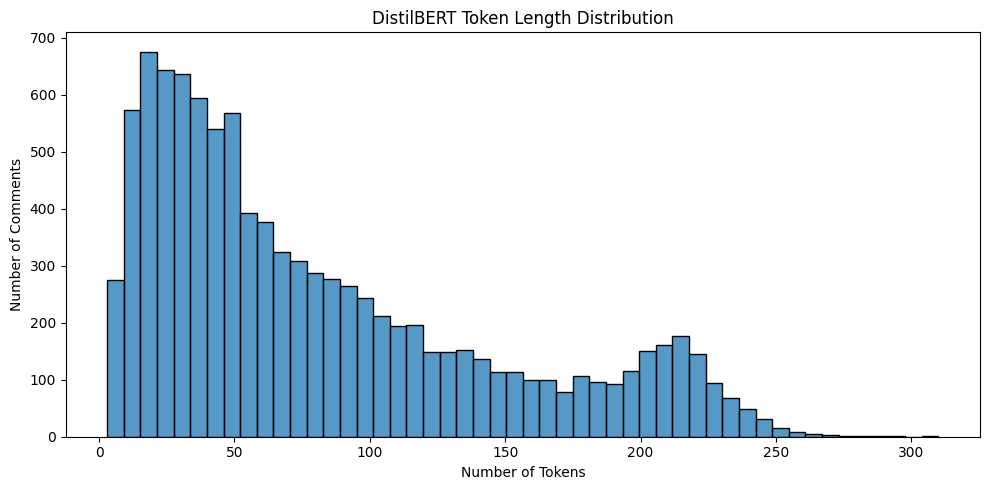

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    lengths,
    bins=50
)

plt.title("DistilBERT Token Length Distribution")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.show()

In [16]:
# Initial experiment
MAX_LENGTH = 128
truncated = np.mean(
    np.array(lengths) > MAX_LENGTH
) * 100

print(
    f"Comments longer than {MAX_LENGTH} tokens: "
    f"{truncated:.2f}%"
)

Comments longer than 128 tokens: 21.88%


### Convert DataFrames back to Hugging Face datasets

In [17]:
train_hf = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

val_hf = Dataset.from_pandas(
    val_df,
    preserve_index=False
)

test_hf = Dataset.from_pandas(
    test_df,
    preserve_index=False
)

print(train_hf)
print(val_hf)
print(test_hf)

Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
    num_rows: 267516
})
Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
    num_rows: 45047
})
Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
    num_rows: 132730
})


In [18]:
def tokenize_function(batch):
    return tokenizer(
        batch["comment_text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

#### Tokenize Train

In [19]:
tokenized_train = train_hf.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing training data"
)
print(tokenized_train)

Tokenizing training data:   0%|          | 0/267516 [00:00<?, ? examples/s]

Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 267516
})


In [20]:
example = tokenized_train[0]

print("Label:", example["label"])
print("Text:", example["comment_text"][:200])
print("Input IDs:", example["input_ids"][:20])
print("Attention mask:", example["attention_mask"][:20])

Label: 0
Text: 🤔
Input IDs: [101, 100, 102]
Attention mask: [1, 1, 1]


#### Tokenize Validation

In [21]:
tokenized_val = val_hf.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing validation data"
)
print(tokenized_val)

Tokenizing validation data:   0%|          | 0/45047 [00:00<?, ? examples/s]

Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 45047
})


#### Tokenize Test

In [22]:
tokenized_test = test_hf.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing test data"
)
print(tokenized_test)

Tokenizing test data:   0%|          | 0/132730 [00:00<?, ? examples/s]

Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 132730
})


In [23]:
assert "label" in tokenized_train.column_names
assert "label" in tokenized_val.column_names
assert "label" in tokenized_test.column_names

print("Labels preserved successfully.")

Labels preserved successfully.


In [24]:
from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

tokenized_train.save_to_disk(
    str(processed_dir / "tokenized_train")
)

tokenized_val.save_to_disk(
    str(processed_dir / "tokenized_validation")
)

tokenized_test.save_to_disk(
    str(processed_dir / "tokenized_test")
)

print("Tokenized datasets saved.")

Saving the dataset (0/1 shards):   0%|          | 0/267516 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/45047 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/132730 [00:00<?, ? examples/s]

Tokenized datasets saved.


In [25]:
config = {
    "model_name": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "label_threshold": 0.5,
    "train_samples": len(tokenized_train),
    "validation_samples": len(tokenized_val),
    "test_samples": len(tokenized_test)
}

config

{'model_name': 'distilbert-base-uncased',
 'max_length': 128,
 'label_threshold': 0.5,
 'train_samples': 267516,
 'validation_samples': 45047,
 'test_samples': 132730}

In [26]:
import json

with open(
    processed_dir / "preparation_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        config,
        f,
        indent=4
    )

print("Configuration saved.")

Configuration saved.
